In [1]:
import os
os.environ['JAX_PLATFORMS'] = 'cuda'

import jax
print(jax.devices())

[CudaDevice(id=0)]


In [2]:
import time
import warnings
import subprocess
import importlib.metadata as imeta
from pathlib import Path

warnings.filterwarnings("ignore")

import jax
import yaml
from jcm import configurations

print(f"JAX version : {jax.__version__}")
print(f"Backend     : {jax.default_backend().upper()}")
print(f"Devices     : {jax.devices()}")

JAX version : 0.10.2
Backend     : GPU
Devices     : [CudaDevice(id=0)]


In [3]:
# loading the configuration
OUTDIR = Path("output")
OUTDIR.mkdir(exist_ok=True)

exp     = configurations.load("speedy-t31")
model   = exp.model
forcing = exp.forcing

print(model)

forcing.ozone_file=auto on a sigma-vertical grid — the packaged and mirror ozone products are interpolated onto hybrid-level pressures and would be mapped level-for-level onto unrelated sigma levels. Falling back to the ANALYTIC ozone profile; supply an on-grid forcing.ozone_file (built for this vertical grid) for production radiation.


Model(dycore=DinosaurDycore, grid=96x48, levels=8, dt=900s, physics=[speedy_flags, speedy_forcing, speedy_humidity, speedy_convection, speedy_large_scale_condensation, speedy_clouds, speedy_shortwave_radiation, speedy_downward_longwave, speedy_surface_flux, speedy_upward_longwave, speedy_vertical_diffusion])


In [4]:
# recording the configuration
def pkg(name):
    try:    return imeta.version(name)
    except: return "n/a"

def git_hash():
    try:    return subprocess.check_output(
                ["git", "rev-parse", "HEAD"], stderr=subprocess.DEVNULL
            ).decode().strip()
    except: return "n/a"

record = {
    "configuration" : "speedy-t31",
    "schedule" : {
        "spinup_years"       : 1,
        "analysis_years"     : 10,
        "timestep_min"       : 15,
        "save_interval_days" : 30,
        "output_averages"    : True,
    },
    "model_repr" : repr(model),
    "packages"   : {p: pkg(p) for p in
                    ["jcm", "jax", "jaxlib", "dinosaur",
                     "flax", "xarray", "netCDF4"]},
    "hardware"   : {
        "backend" : jax.default_backend(),
        "devices" : [str(d) for d in jax.devices()],
    },
    "git_hash"    : git_hash(),
    "run_started" : time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
}

record_path = OUTDIR / "config_record.yaml"
record_path.write_text(yaml.dump(record, default_flow_style=False, sort_keys=False))

print(yaml.dump(record, default_flow_style=False, sort_keys=False))

configuration: speedy-t31
schedule:
  spinup_years: 1
  analysis_years: 10
  timestep_min: 15
  save_interval_days: 30
  output_averages: true
model_repr: Model(dycore=DinosaurDycore, grid=96x48, levels=8, dt=900s, physics=[speedy_flags,
  speedy_forcing, speedy_humidity, speedy_convection, speedy_large_scale_condensation,
  speedy_clouds, speedy_shortwave_radiation, speedy_downward_longwave, speedy_surface_flux,
  speedy_upward_longwave, speedy_vertical_diffusion])
packages:
  jcm: 3.0.0
  jax: 0.10.2
  jaxlib: 0.10.2
  dinosaur: 1.5.1
  flax: 0.12.8
  xarray: 2026.9.0
  netCDF4: 1.7.5
hardware:
  backend: gpu
  devices:
  - cuda:0
git_hash: n/a
run_started: '2026-10-26T01:28:37Z'



In [5]:
# 1-year spin up
# Extra kwargs from the configuration we don't override
extra = {
    k: v for k, v in exp.run_kwargs.items()
    if k not in ("total_time", "end_time", "save_interval",
                 "forcing", "output_averages")
}

print("Running spin-up (1 year) …")
t0 = time.perf_counter()

spinup = model.run(
    forcing         = forcing,
    total_time      = 360,
    save_interval   = 30,      # one snapshot per ~month
    output_averages = True,    # each snapshot is a 30-day mean
    **extra,
)
jax.effects_barrier()

t_spinup = time.perf_counter() - t0
print(f"Spin-up done in {t_spinup/60:.1f} min")

Running spin-up (1 year) …
Spin-up done in 1.3 min


In [6]:
### Working on ERF as a Function

In [7]:
import time, warnings
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
warnings.filterwarnings('ignore')

import jax
from jcm import configurations

print(f'Backend : {jax.default_backend().upper()}')
print(f'Device  : {jax.devices()[0]}')

OUTDIR = Path('output/erf')
OUTDIR.mkdir(parents=True, exist_ok=True)

Backend : GPU
Device  : cuda:0


In [8]:
import inspect
import importlib

# Read the SPEEDY forcing / radiation source
try:
    import jcm.physics.forcing.speedy_forcing as sf
    print(inspect.getsource(sf))
except ModuleNotFoundError:
    # Try alternate paths depending on jcm version
    import jcm.physics.speedy.radiation as sf
    print(inspect.getsource(sf))

from jcm.terrain import TerrainData
from jcm.physics.speedy.params import Parameters
from jcm.physics.speedy.physics_data import ablco2_ref, PhysicsData
from jcm.forcing import ForcingData, DEFAULT_CO2_VMR_PPMV, land_snow_cover
from jcm.physics_interface import PhysicsState, PhysicsTendency
from jcm.physics.radiation.speedy_shortwave import get_zonal_average_fields
import jax.numpy as jnp


# Reference CO2 concentration (ppmv) at which `ablco2_ref` is defined. SPEEDY's
# original Fortran tuned `ablco2_ref` for ~1990s atmosphere (~360 ppmv); we
# anchor our linear scaling to that baseline so a `forcing.co2_vmr` of 360
# ppmv reproduces the legacy un-perturbed (`increase_co2=False`) behavior
# exactly.
CO2_VMR_REF_PPMV = DEFAULT_CO2_VMR_PPMV  # 360.0


def ablco2_from_co2_vmr(co2_vmr_ppmv: jnp.ndarray) -> jnp.ndarray:
    """CO2 absorptivity used by SPEEDY shortwave/longwave, derived from
    a CO2 mixing ratio (ppmv).

    Linear scaling against the reference: `ablco2 = ablco2_ref * C /

In [9]:
from jcm.forcing import DEFAULT_CO2_VMR_PPMV
co2_ctrl = DEFAULT_CO2_VMR_PPMV
print(f'Control CO₂ : {co2_ctrl} ppm')
print(model)

Control CO₂ : 420.0 ppm
Model(dycore=DinosaurDycore, grid=96x48, levels=8, dt=900s, physics=[speedy_flags, speedy_forcing, speedy_humidity, speedy_convection, speedy_large_scale_condensation, speedy_clouds, speedy_shortwave_radiation, speedy_downward_longwave, speedy_surface_flux, speedy_upward_longwave, speedy_vertical_diffusion])


In [10]:
# defining our experiment
MULTIPLIERS  = [1.0, 0.5, 2.0, 4.0, 8.0]   # 1.0 = control
TOTAL_DAYS   = 5 * 360    # 5 × 360-day years per run
DISCARD_SNAP = 12         # drop first 12 monthly snapshots (year 1)

extra = {
    k: v for k, v in exp.run_kwargs.items()
    if k not in ('total_time', 'end_time', 'save_interval',
                 'forcing', 'output_averages', 'co2_vmr')
}

print('CO₂ levels:')
for m in MULTIPLIERS:
    print(f'  {m}×  =  {co2_ctrl * m:.1f} ppm')

CO₂ levels:
  1.0×  =  420.0 ppm
  0.5×  =  210.0 ppm
  2.0×  =  840.0 ppm
  4.0×  =  1680.0 ppm
  8.0×  =  3360.0 ppm


In [11]:
# Running each CO2 level
results = {}

for mult in MULTIPLIERS:
    co2_val = co2_ctrl * mult
    label   = f'{mult}x'
    nc_path = OUTDIR / f'erf_{label}.nc'

    if nc_path.exists():
        print(f'{label}: loading from cache')
        results[mult] = xr.open_dataset(nc_path)
        continue

    print(f'\n── {label}  ({co2_val:.1f} ppm) ──────────────────────────────')
    t0 = time.perf_counter()

    # Patch co2_vmr onto the forcing object for this run
    forcing_co2 = forcing.replace(co2_vmr=co2_val)

    run = model.run(
        forcing         = forcing_co2,
        total_time      = TOTAL_DAYS,
        save_interval   = 30,
        output_averages = True,
        **extra,
    )
    jax.effects_barrier()

    print(f'   done in {(time.perf_counter()-t0)/60:.1f} min')

    ds = run.to_xarray()
    ds.to_netcdf(nc_path)
    results[mult] = ds
    print(f'   saved → {nc_path}')

print('\nAll runs complete.')


── 1.0x  (420.0 ppm) ──────────────────────────────
   done in 5.4 min
   saved → output/erf/erf_1.0x.nc

── 0.5x  (210.0 ppm) ──────────────────────────────
   done in 5.1 min
   saved → output/erf/erf_0.5x.nc

── 2.0x  (840.0 ppm) ──────────────────────────────
   done in 5.1 min
   saved → output/erf/erf_2.0x.nc

── 4.0x  (1680.0 ppm) ──────────────────────────────
   done in 5.1 min
   saved → output/erf/erf_4.0x.nc

── 8.0x  (3360.0 ppm) ──────────────────────────────
   done in 5.1 min
   saved → output/erf/erf_8.0x.nc

All runs complete.


In [14]:
def global_mean(da):
    """Latitude-weighted global mean over the spatial dimensions."""
    lat_dim = 'lat' if 'lat' in da.dims else 'latitude'
    lon_dim = 'lon' if 'lon' in da.dims else 'longitude'
    w = np.cos(np.deg2rad(da[lat_dim]))
    return da.weighted(w).mean([lat_dim, lon_dim])


def toa_net(ds):
    """Return global-mean TOA net downward flux (SW_down - SW_up - LW_up).
    Variable names vary by jcm version; try the most common ones."""
    print('  Available variables:', list(ds.data_vars))

    # Try to find TOA net flux directly
    for v in ['toa_net_flux', 'toa_net', 'net_toa', 'rnt']:
        if v in ds: return global_mean(ds[v])

    # Build from components: net = SW_net_toa - OLR
    sw, lw = None, None
    for v in ['toa_sw_net','sw_toa_net','rsnt','netSW_toa']:
        if v in ds: sw = global_mean(ds[v]); break
    for v in ['olr','toa_lw_up','rlut','OLR']:
        if v in ds: lw = global_mean(ds[v]); break

    if sw is not None and lw is not None:
        return sw - lw

    raise KeyError(
        f'Cannot find TOA flux variables. Available: {list(ds.data_vars)}\n'
        'Set toa_net manually below.'
    )


# Compute per-run time series, discard year 1, then mean and std
erf_mean = {}
erf_se   = {}

for mult, ds in results.items():
    print(f'\n{mult}×:')
    flux   = toa_net(ds)                    # shape: (time,)
    flux_2_5 = flux.isel(time=slice(12, None))   # drop year 1 (12 monthly means)
    # Annual means from monthly data
    ann  = flux_2_5.values.reshape(-1, 12).mean(axis=1)   # shape: (4,)
    erf_mean[mult] = ann.mean()
    erf_se[mult]   = ann.std(ddof=1) / np.sqrt(len(ann))
    print(f'   TOA net flux: {erf_mean[mult]:.3f} ± {erf_se[mult]:.3f} W m⁻²')

# ERF = anomaly from control
ctrl_flux = erf_mean[1.0]
print(f'\nControl TOA net: {ctrl_flux:.3f} W m⁻²')

multipliers = sorted(results.keys())
erf   = np.array([erf_mean[m] - ctrl_flux for m in multipliers])
erf_e = np.array([erf_se[m]               for m in multipliers])
lnr   = np.array([np.log(m)               for m in multipliers])   # ln(C/C₀)

for m, e, s, l in zip(multipliers, erf, erf_e, lnr):
    print(f'  {m}×  ln(C/C₀)={l:+.3f}  ERF={e:+.3f} ± {s:.3f} W m⁻²')


1.0×:
  SW TOA: {'units': 'W/m²', 'description': 'Net downward flux at top of atmosphere', 'cell_methods': 'time: mean'}
  LW TOA: {'units': 'W/m²', 'description': 'Outgoing flux of long-wave radiation at the top of the atmosphere', 'cell_methods': 'time: mean'}
   TOA net flux: 5.197 ± 0.084 W m⁻²

0.5×:
  SW TOA: {'units': 'W/m²', 'description': 'Net downward flux at top of atmosphere', 'cell_methods': 'time: mean'}
  LW TOA: {'units': 'W/m²', 'description': 'Outgoing flux of long-wave radiation at the top of the atmosphere', 'cell_methods': 'time: mean'}
   TOA net flux: -4.958 ± 0.035 W m⁻²

2.0×:
  SW TOA: {'units': 'W/m²', 'description': 'Net downward flux at top of atmosphere', 'cell_methods': 'time: mean'}
  LW TOA: {'units': 'W/m²', 'description': 'Outgoing flux of long-wave radiation at the top of the atmosphere', 'cell_methods': 'time: mean'}
   TOA net flux: 12.298 ± 0.053 W m⁻²

4.0×:
  SW TOA: {'units': 'W/m²', 'description': 'Net downward flux at top of atmosphere', 'ce

NorESM2 mean CO2 ERF (last 20 yr): 1.55 W m⁻²  at ln(C/C₀)=0.39


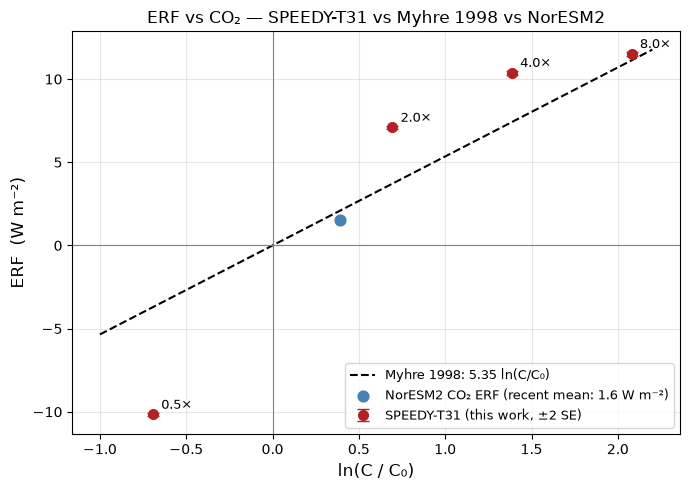

In [24]:
ln_range = np.linspace(-1.0, 2.2, 200)
myhre    = 5.35 * ln_range

# NorESM2: average CO2 ERF over last 20 years of record as a reference point
noresm_recent = noresm_erf[noresm_erf['year'] >= noresm_erf['year'].max() - 20]['CO2'].mean()
noresm_ln     = np.log(420 / 284)   # present-day / pre-industrial CO2
print(f'NorESM2 mean CO2 ERF (last 20 yr): {noresm_recent:.2f} W m⁻²  at ln(C/C₀)={noresm_ln:.2f}')

fig, ax = plt.subplots(figsize=(7, 5))

# Myhre 1998
ax.plot(ln_range, myhre, 'k--', lw=1.5, label='Myhre 1998: 5.35 ln(C/C₀)')

# NorESM2 full time series
ax.plot(np.log((284 + noresm_erf['CO2'].cumsum() * 0 + 
               noresm_erf['year'].map(lambda y: (y-1850)*0)) / 284),  
        noresm_erf['CO2'],
        color='steelblue', lw=0.5, alpha=0.4)

# NorESM2 single reference point
ax.scatter(noresm_ln, noresm_recent, color='steelblue', s=60, zorder=5,
           label=f'NorESM2 CO₂ ERF (recent mean: {noresm_recent:.1f} W m⁻²)')

# SPEEDY results
mask = np.array(multipliers) != 1.0
ax.errorbar(
    lnr[mask], erf[mask], yerr=2*erf_e[mask],
    fmt='o', color='firebrick', ms=7, capsize=4, lw=1.5,
    label='SPEEDY-T31 (this work, ±2 SE)'
)
for m, l, e in zip(np.array(multipliers)[mask], lnr[mask], erf[mask]):
    ax.annotate(f'{m}×', (l, e), textcoords='offset points',
                xytext=(6, 4), fontsize=9)

ax.axhline(0, color='grey', lw=0.8)
ax.axvline(0, color='grey', lw=0.8)
ax.set_xlabel('ln(C / C₀)', fontsize=12)
ax.set_ylabel('ERF  (W m⁻²)', fontsize=12)
ax.set_title('ERF vs CO₂ — SPEEDY-T31 vs Myhre 1998 vs NorESM2', fontsize=12)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('output/erf/erf_co2.png', dpi=150)
plt.show()


In [25]:
ds_4x   = xr.open_dataset('output/erf/erf_4.0x.nc')
ds_ctrl = xr.open_dataset('output/erf/erf_1.0x.nc')
print(ds_4x.data_vars)

Data variables:
    u_wind                                                  (time, level, lon, lat) float32 9MB ...
    v_wind                                                  (time, level, lon, lat) float32 9MB ...
    temperature                                             (time, level, lon, lat) float32 9MB ...
    specific_humidity                                       (time, level, lon, lat) float32 9MB ...
    geopotential                                            (time, level, lon, lat) float32 9MB ...
    normalized_surface_pressure                             (time, lon, lat) float32 1MB ...
    condensation.precls                                     (time, lon, lat) float32 1MB ...
    condensation.dtlsc                                      (time, level, lon, lat) float32 9MB ...
    condensation.dqlsc                                      (time, level, lon, lat) float32 9MB ...
    convection.se                                           (time, level, lon, lat) float32 9MB ..

4× ERF: 10.39 W m⁻²
Global-mean ΔP          : -82.4501 mm/day
Land-mean   ΔP          : 147.2013 mm/day
Land-mean   ΔT          : 0.0000 K
Global ΔP per W m⁻² ERF : -7.9321 mm/day per W m⁻²


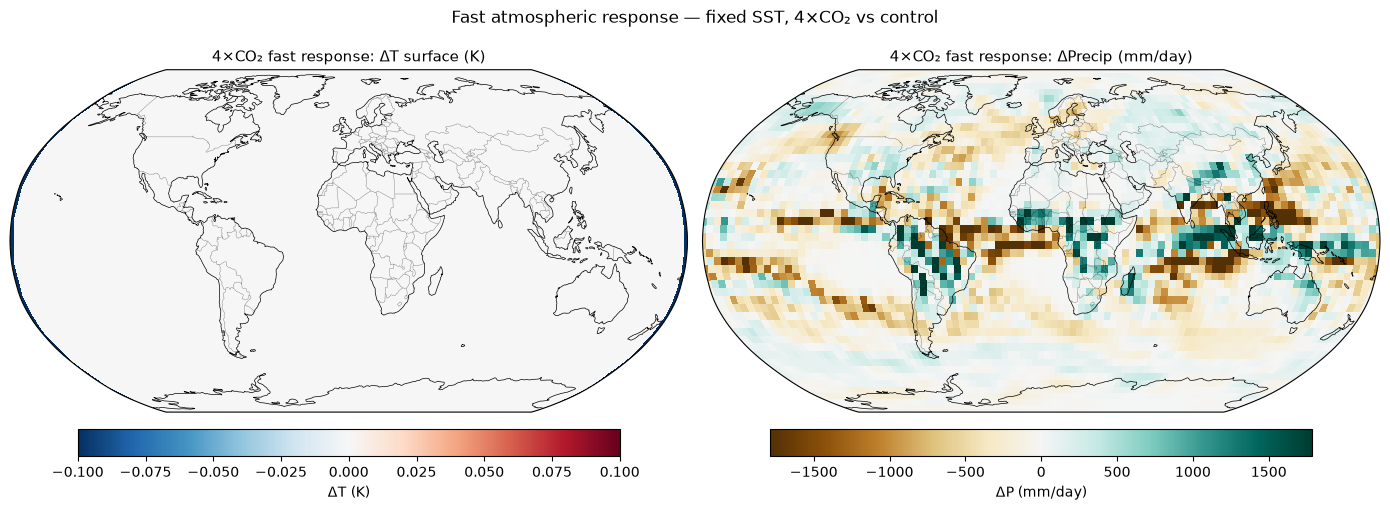

Saved → output/erf/fast_response_4xCO2.png


In [26]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

# ── Load and time-mean (discard year 1) ───────────────────────────────────────
ds_4x   = xr.open_dataset('output/erf/erf_4.0x.nc').isel(time=slice(12, None))
ds_ctrl = xr.open_dataset('output/erf/erf_1.0x.nc').isel(time=slice(12, None))

# ── Time means ────────────────────────────────────────────────────────────────
def tmean(ds, var):
    return ds[var].mean('time')

# Surface temperature (K)
dt   = tmean(ds_4x, 'surface_flux.tsfc') - tmean(ds_ctrl, 'surface_flux.tsfc')

# Total precipitation = convective + large-scale (kg m-2 s-1)
prec_4x   = tmean(ds_4x,   'convection.precnv') + tmean(ds_4x,   'condensation.precls')
prec_ctrl = tmean(ds_ctrl, 'convection.precnv') + tmean(ds_ctrl, 'condensation.precls')
dp = prec_4x - prec_ctrl

# ── Land mask from terrain fmask (1=land, 0=ocean) ───────────────────────────
# Use alb_l variability as a proxy if fmask not available
# alb_l > 0 over land; albsea is ~0.07 everywhere over ocean
# Better: use the forcing terrain object already loaded
try:
    fmask = xr.DataArray(
        np.array(forcing.terrain.fmask),
        dims=['lon', 'lat']
    )
except Exception:
    # fallback: land where surface albedo is meaningfully different from sea
    fmask = (tmean(ds_ctrl, 'mod_radcon.alb_l') > 0.1).astype(float)

land = fmask > 0.5

# ── ERF for 4x from earlier results ──────────────────────────────────────────
erf_4x = erf[multipliers.index(4.0)]
print(f'4× ERF: {erf_4x:.2f} W m⁻²')

# ── Global and land-only means ────────────────────────────────────────────────
def gmean(da):
    lat = da.lat if 'lat' in da.dims else da.latitude
    w   = np.cos(np.deg2rad(lat))
    return float(da.weighted(w).mean(['lon', 'lat']))

def lmean(da, mask):
    lat = da.lat if 'lat' in da.dims else da.latitude
    w   = np.cos(np.deg2rad(lat)) * mask
    return float(da.weighted(w).mean(['lon', 'lat']))

# Convert precip to mm/day (multiply kg m-2 s-1 by 86400)
dp_mmday = dp * 86400

gm_dp   = gmean(dp_mmday)
lm_dp   = lmean(dp_mmday, land)
lm_dt   = lmean(dt, land)

print(f'Global-mean ΔP          : {gm_dp:.4f} mm/day')
print(f'Land-mean   ΔP          : {lm_dp:.4f} mm/day')
print(f'Land-mean   ΔT          : {lm_dt:.4f} K')
print(f'Global ΔP per W m⁻² ERF : {gm_dp/erf_4x:.4f} mm/day per W m⁻²')

# ── Plot ──────────────────────────────────────────────────────────────────────
proj = ccrs.Robinson()

fig, axes = plt.subplots(1, 2, figsize=(14, 5),
                         subplot_kw={'projection': proj})

# Coords
lon = ds_4x.lon.values
lat = ds_4x.lat.values

def make_map(ax, data, title, cmap, label, vmax=None):
    vmax = vmax or float(np.abs(data).quantile(0.98))
    im = ax.pcolormesh(lon, lat, data.values.T,
                       transform=ccrs.PlateCarree(),
                       cmap=cmap, vmin=-vmax, vmax=vmax)
    ax.add_feature(cfeature.COASTLINE, lw=0.5)
    ax.add_feature(cfeature.BORDERS,   lw=0.3, alpha=0.5)
    ax.set_title(title, fontsize=11)
    plt.colorbar(im, ax=ax, orientation='horizontal',
                 pad=0.04, label=label, shrink=0.8)

make_map(axes[0], dt,
         '4×CO₂ fast response: ΔT surface (K)',
         'RdBu_r', 'ΔT (K)')

make_map(axes[1], dp_mmday,
         '4×CO₂ fast response: ΔPrecip (mm/day)',
         'BrBG', 'ΔP (mm/day)')

plt.suptitle('Fast atmospheric response — fixed SST, 4×CO₂ vs control',
             fontsize=12, y=1.01)
plt.tight_layout()
# plt.savefig('output/erf/fast_response_4xCO2.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → output/erf/fast_response_4xCO2.png')